# 05 · Funnel plots — who is a true outlier?

Question 3. A small hospital can look extreme just by chance. A funnel plot puts each
hospital's rate (y) against its patient volume (x) with control limits that widen at low
volume, so we can separate real outliers from noise.

We plot the four measures with the most reporting hospitals. **Caveat:** CMS rates are
risk-standardized model estimates, so binomial control limits are an approximation. We
cross-check every flag against CMS's own 95% interval estimates.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src.viz import apply_style, CATEGORICAL, WORSE, MUTED, INK2, SURFACE
apply_style()

INTERIM = Path("../data/interim")
FIG = Path("../reports/figures")

unplanned = pd.read_csv(INTERIM / "unplanned_visits_nm.csv", dtype={"Facility ID": str})
complications = pd.read_csv(INTERIM / "complications_death_nm.csv", dtype={"Facility ID": str})

MEASURES = [
    ("Hybrid_HWM", complications, "Hospital-wide mortality"),
    ("MORT_30_PN", complications, "Pneumonia mortality"),
    ("READM_30_PN", unplanned, "Pneumonia readmission"),
    ("READM_30_HF", unplanned, "Heart-failure readmission"),
]

## The funnel plots

Center line = NM volume-weighted average. Dashed = 95% limits, dotted = 99.8%. A point
outside the limits is a candidate outlier; orange = past 95%, red = past 99.8%.

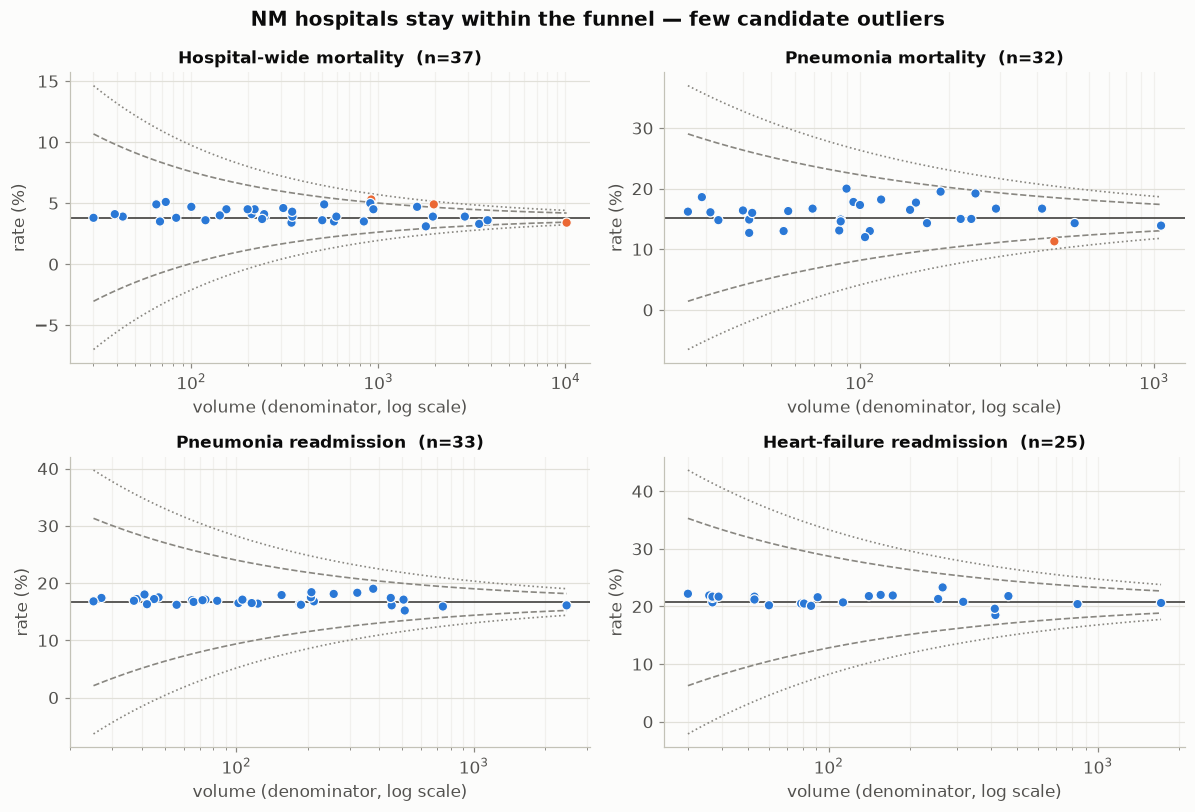

In [2]:
def funnel(ax, measure_id, df, title):
    d = df[(df["Measure ID"] == measure_id) & df["score"].notna()
           & df["denominator"].notna()].copy()
    center = np.average(d["score"], weights=d["denominator"])
    p = center / 100

    ns = np.logspace(np.log10(d["denominator"].min()),
                     np.log10(d["denominator"].max()), 200)
    for z, ls in [(1.96, "--"), (3.09, ":")]:
        se = np.sqrt(p * (1 - p) / ns) * 100
        ax.plot(ns, center + z * se, ls, color=MUTED, lw=1.1)
        ax.plot(ns, center - z * se, ls, color=MUTED, lw=1.1)
    ax.axhline(center, color=INK2, lw=1.2)

    se_pt = np.sqrt(p * (1 - p) / d["denominator"]) * 100
    z_pt = (d["score"] - center).abs() / se_pt
    color = np.where(z_pt > 3.09, WORSE,
                     np.where(z_pt > 1.96, CATEGORICAL[7], CATEGORICAL[0]))
    ax.scatter(d["denominator"], d["score"], c=color, s=38, zorder=3,
               edgecolor=SURFACE, linewidth=0.8)
    ax.set_xscale("log")
    ax.set_title(f"{title}  (n={len(d)})", fontsize=11)
    ax.set_xlabel("volume (denominator, log scale)")
    ax.set_ylabel("rate (%)")
    ax.grid(True, which="both", axis="x", alpha=0.4)
    return int((z_pt > 1.96).sum()), int((z_pt > 3.09).sum())

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, (mid, df, title) in zip(axes.ravel(), MEASURES):
    funnel(ax, mid, df, title)
fig.suptitle("NM hospitals stay within the funnel — few candidate outliers",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "fig_funnels.png")
plt.show()

## Cross-check against CMS's own interval estimates

A funnel flag is only convincing if CMS's own 95% interval for that hospital also sits
clearly away from the NM average. Count, per measure: how many hospitals fall outside the
funnel limits, and how many have a CMS interval that excludes the NM average.

In [3]:
rows = []
for mid, df, title in MEASURES:
    d = df[(df["Measure ID"] == mid) & df["score"].notna()
           & df["denominator"].notna()].copy()
    center = np.average(d["score"], weights=d["denominator"])
    p = center / 100
    se_pt = np.sqrt(p * (1 - p) / d["denominator"]) * 100
    z_pt = (d["score"] - center).abs() / se_pt
    cms_excludes = ((d["higher_estimate"] < center) | (d["lower_estimate"] > center)).sum()
    rows.append({
        "measure": title,
        "hospitals": len(d),
        "NM avg %": round(center, 1),
        "outside 95%": int((z_pt > 1.96).sum()),
        "outside 99.8%": int((z_pt > 3.09).sum()),
        "CMS interval excludes NM avg": int(cms_excludes),
    })

check = pd.DataFrame(rows)
display(check)

,measure,hospitals,NM avg %,outside 95%,outside 99.8%,CMS interval excludes NM avg
0,Hospital-wide mortality,37,3.8,3,0,0
1,Pneumonia mortality,32,15.2,1,0,0
2,Pneumonia readmission,33,16.7,0,0,0
3,Heart-failure readmission,25,20.8,0,0,0


## Takeaway — outliers (question 3)

- **No robust outliers.** Across all four measures
  - **no** hospital falls outside the 99.8% control limits
  - **no** hospital's CMS 95% interval excludes the NM average
- The handful of points past the 95% line (3 on hospital-wide mortality, 1 on pneumonia
  mortality) are **not confirmed** by CMS's own intervals — consistent with chance given
  their volume.
- **Why volume matters:** the funnel is wide at low volume, so a small hospital with a
  high-looking rate is usually within expected variation. Judging hospitals on raw rates
  alone would wrongly single these out.
- **For a health plan:** there's no single NM hospital to target as a clear outlier on
  these measures. Focus should be on the **coverage gap** (notebook 03) and on domains
  with the most Worse-than-national verdicts (readmissions, notebook 04), using the plan's
  own claims data where CMS can't measure.